In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import gammaln, betaln, hyp2f1
from scipy.optimize import minimize
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, brier_score_loss

In [7]:
import os
for carpeta, _, archivos in os.walk("data"):
    print(carpeta, archivos)

data ['Online_Retail.xlsx']
data\Raw ['CDNOW_sample.txt', 'read_me_CDNOW_sample.txt']


In [9]:
import os
for carpeta, _, archivos in os.walk("data"):
    print(carpeta, archivos)

data ['Online_Retail.xlsx']
data\Raw ['CDNOW_sample.txt', 'read_me_CDNOW_sample.txt']


In [10]:
raw = pd.read_csv("data/Raw/CDNOW_sample.txt", sep=r"\s+", header=None,
                  names=["id_base", "id", "fecha", "cds", "monto"])
raw["fecha"] = pd.to_datetime(raw["fecha"].astype(str), format="%Y%m%d")

# Compras del mismo día cuentan como una sola
compras = raw[["id", "fecha"]].drop_duplicates()

fin_cal = pd.Timestamp("1997-09-30")
fin_hold = pd.Timestamp("1998-06-30")
cal = compras[compras.fecha <= fin_cal]
hold = compras[(compras.fecha > fin_cal) & (compras.fecha <= fin_hold)]

g = cal.groupby("id").fecha
df = pd.DataFrame({"primera": g.min(), "ultima": g.max(), "n": g.count()})
df["x"] = df.n - 1
df["tx"] = (df.ultima - df.primera).dt.days / 7
df["T"] = (fin_cal - df.primera).dt.days / 7
df["x_star"] = hold.groupby("id").size().reindex(df.index).fillna(0).astype(int)

print(len(df))   # debe ser 2357
df.head()

2357


,primera,ultima,n,x,tx,T,x_star
id,,,,,,,
1,1997-01-01,1997-08-02,3,2,30.428571,38.857143,1
2,1997-01-01,1997-01-13,2,1,1.714286,38.857143,0
3,1997-01-01,1997-01-01,1,0,0.000000,38.857143,0
4,1997-01-01,1997-01-01,1,0,0.000000,38.857143,0
5,1997-01-01,1997-01-01,1,0,0.000000,38.857143,0


In [13]:
def p_vivo(x, tx, T, r, alpha, a, b):
    x = np.asarray(x, dtype=float)
    termino = np.where(
        x > 0,
        a / (b + np.maximum(x, 1) - 1) * ((alpha + T) / (alpha + tx)) ** (r + x),
        0.0,
    )
    return 1 / (1 + termino)

df["p_vivo"] = p_vivo(df.x, df.tx, df["T"], r, alpha, a, b)
df["Z"] = (df.x_star >= 1).astype(int)

print("Tasa base:", df.Z.mean())

Tasa base: 0.29019940602460753


In [12]:
r, alpha, a, b = 0.243, 4.414, 0.793, 2.426

[[ 254 1419]
 [ 139  545]]


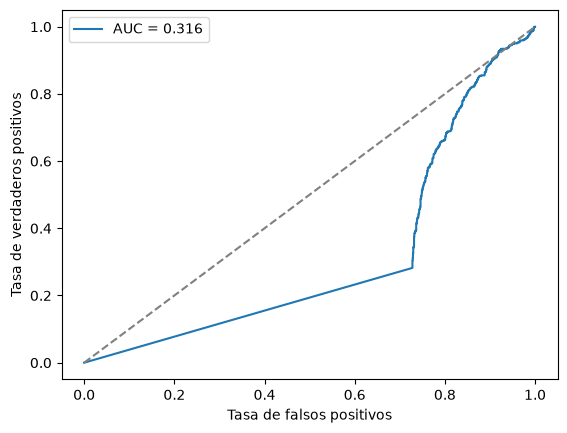

In [14]:
pred = (df.p_vivo >= 0.5).astype(int)
print(confusion_matrix(df.Z, pred))   # filas = real (0,1), columnas = predicho (0,1)

fpr, tpr, _ = roc_curve(df.Z, df.p_vivo)
auc = roc_auc_score(df.Z, df.p_vivo)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.show()

In [15]:
cero = df[df.x == 0]
print(len(cero), "clientes con x = 0")
print(cero.p_vivo.describe())
print("Fracción de x = 0 que compró en el holdout:", cero.Z.mean())

1411 clientes con x = 0
count    1411.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: p_vivo, dtype: float64
Fracción de x = 0 que compró en el holdout: 0.13678242381289865


In [16]:
print("x > 0:", df[df.x > 0].Z.mean())

x > 0: 0.5190274841437632


### 4.2 ¿Por qué el AUC es 0.316?

En el BG/NBD un cliente solo puede "morir" justo después de una compra
repetida. Un cliente con x = 0 nunca ha tenido esa oportunidad, así que
el modelo le asigna P(vivo) = 1 sin importar cuánto tiempo lleve sin comprar.

En CDNOW, 1,411 de 2,357 clientes (60%) tienen x = 0 y todos reciben
P(vivo) = 1, el puntaje máximo. Sin embargo, solo el 13.7% de ellos compró
en el holdout, menos que la tasa base (29%). Los clientes con x > 0 tienen
P(vivo) < 1 (el modelo los "castiga" por llevar tiempo sin comprar), pero
son compradores más activos y compran más en el holdout.

Resultado: el puntaje más alto se concentra en quienes menos compran, y el
clasificador ordena al revés (AUC < 0.5).

**Conclusión:** P(vivo) responde "¿sigue activo?", no "¿va a comprar?".
Un cliente vivo con una tasa λ muy baja casi no compra. Para predecir
compras hay que combinar P(vivo) con la tasa de compra, que es el 4.3.

In [18]:
def p_compra(x, tx, T, tau, r, alpha, a, b):
    return p_vivo(x, tx, T, r, alpha, a, b) * (1 - ((alpha + T) / (alpha + T + tau)) ** (r + x))

df["p_compra"] = p_compra(df.x, df.tx, df["T"], 39, r, alpha, a, b)
print(df.p_compra.describe())

count    2.357000e+03
mean     2.619305e-01
std      1.929785e-01
min      2.521524e-11
25%      1.550520e-01
50%      1.681551e-01
75%      3.069442e-01
max      9.692184e-01
Name: p_compra, dtype: float64


### 4.3 La probabilidad correcta de comprar

P(vivo) no es la probabilidad de comprar, así que hay que construir esa
probabilidad. Lo que queremos es P(Z = 1 | x, tx, T): que el cliente compre
al menos una vez en las τ = 39 semanas del holdout.

**Paso 1: separar vivo y muerto.** Un cliente muerto no compra, así que
P(Z=1) = P(vivo) · P(Z=1 | vivo).

**Paso 2: qué pasa con un cliente vivo.** En el BG/NBD solo se puede morir
justo después de una compra. Entonces un cliente vivo que no compra sigue
vivo. Y si compra en el holdout ya cuenta como Z = 1, aunque muera después.
Por eso, dado que está vivo, Z = 0 solo ocurre si no hizo ninguna compra en
las τ semanas.

**Paso 3: posterior de λ.** Dado que el cliente está vivo, la distribución
posterior de su tasa de compra es λ | x, T ~ Gamma(r + x, α + T).

**Paso 4: probabilidad de cero compras.** Con λ fija, P(0 compras en τ) = e^(−λτ).
Promediando con la posterior Gamma (mezcla gamma–Poisson):

$$P(0 \text{ compras en } \tau \mid \text{vivo}) = \int_0^\infty e^{-\lambda\tau}\,
\text{Gamma}(\lambda;\, r+x,\, \alpha+T)\, d\lambda
= \left(\frac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}$$

**Paso 5: juntar todo.**

$$P(Z=1 \mid x, t_x, T) = P(\text{vivo}\mid x,t_x,T)\left[1-\left(\frac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}\right]$$

La primera parte dice si el cliente sigue activo, y el corchete dice qué tan
probable es que compre en 39 semanas si está activo. Antes solo teníamos la
primera.

In [20]:
print("AUC P(vivo):  ", roc_auc_score(df.Z, df.p_vivo))
print("AUC P(Z=1):   ", roc_auc_score(df.Z, df.p_compra))

AUC P(vivo):   0.3157916583648801
AUC P(Z=1):    0.756887424278968


In [21]:
def simular(n, r, alpha, a, b, T_vals, tau=39, seed=0):
    rng = np.random.default_rng(seed)
    lam = rng.gamma(shape=r, scale=1/alpha, size=n)   # λ ~ Gamma(r, tasa α)
    p = rng.beta(a, b, size=n)                        # p ~ Beta(a, b)
    T = rng.choice(T_vals, size=n)
    x = np.zeros(n); tx = np.zeros(n); xs = np.zeros(n)

    for i in range(n):
        t = 0.0
        while True:
            t += rng.exponential(1 / lam[i])          # tiempo hasta la siguiente compra
            if t > T[i] + tau:
                break
            if t <= T[i]:                             # compra en calibración
                x[i] += 1
                tx[i] = t
            else:                                     # compra en holdout
                xs[i] += 1
            if rng.random() < p[i]:                   # muere justo después de comprar
                break

    return pd.DataFrame({"x": x, "tx": tx, "T": T, "x_star": xs})

In [22]:
sim = simular(20000, r, alpha, a, b, df["T"].values, tau=39, seed=1)
sim["Z"] = (sim.x_star >= 1).astype(int)
sim["p_compra"] = p_compra(sim.x, sim.tx, sim["T"], 39, r, alpha, a, b)

print("Tasa simulada:", sim.Z.mean())
print("Promedio de la fórmula:", sim.p_compra.mean())

Tasa simulada: 0.2567
Promedio de la fórmula: 0.2604276699696795


        formula  simulado
decil                    
1      0.117683    0.1285
2      0.149807    0.1430
3      0.154858    0.1470
4      0.159796    0.1490
5      0.165113    0.1630
6      0.170570    0.1615
7      0.183676    0.1870
8      0.304487    0.2960
9      0.452225    0.4510
10     0.746063    0.7410


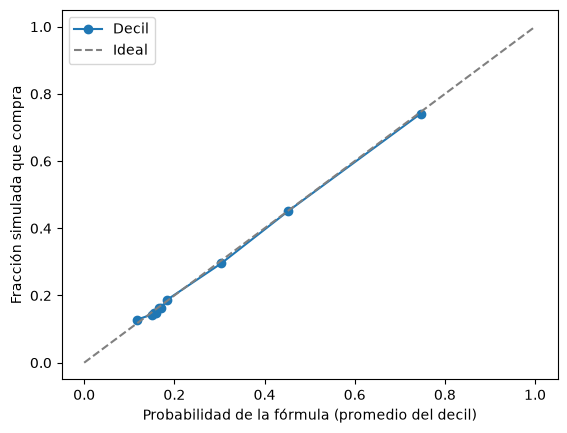

In [23]:
sim["decil"] = pd.qcut(sim.p_compra.rank(method="first"), 10, labels=False) + 1
tab = sim.groupby("decil").agg(formula=("p_compra", "mean"), simulado=("Z", "mean"))
print(tab)

plt.plot(tab.formula, tab.simulado, "o-", label="Decil")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
plt.xlabel("Probabilidad de la fórmula (promedio del decil)")
plt.ylabel("Fracción simulada que compra")
plt.legend()
plt.show()

### 4.4 Verificación por simulación

Para comprobar la fórmula del 4.3 simulé 20,000 clientes con los parámetros
estimados (r, α, a, b), siguiendo la historia del BG/NBD: cada cliente tiene
su λ y su p, compra como un proceso de Poisson y puede morir después de cada
compra. Con la misma ventana de calibración (T) y 39 semanas de holdout,
comparé la probabilidad que da la fórmula contra la fracción de clientes que
realmente compró, agrupando por deciles.

[Aquí escribe lo que viste: si las columnas coinciden, cuánto se separan en
el decil más alto o más bajo, y qué significa eso para la fórmula.]

In [25]:
auc_modelo = roc_auc_score(df.Z, df.p_compra)
auc_tx = roc_auc_score(df.Z, df.tx)   # más alto = compró más recientemente
auc_x = roc_auc_score(df.Z, df.x)     # más alto = más compras repetidas

print("AUC P(Z=1):", round(auc_modelo, 3))
print("AUC recencia tx:", round(auc_tx, 3))
print("AUC frecuencia x:", round(auc_x, 3))

AUC P(Z=1): 0.757
AUC recencia tx: 0.763
AUC frecuencia x: 0.758


In [26]:
brier_modelo = brier_score_loss(df.Z, df.p_compra)
brier_base = brier_score_loss(df.Z, np.full(len(df), df.Z.mean()))

print("Brier modelo:", round(brier_modelo, 4))
print("Brier tasa base:", round(brier_base, 4))

Brier modelo: 0.1612
Brier tasa base: 0.206


       predicha  observada
decil                     
1      0.122092   0.199153
2      0.150048   0.097458
3      0.155151   0.136170
4      0.159929   0.114407
5      0.165245   0.161017
6      0.170636   0.170213
7      0.181444   0.237288
8      0.304339   0.438298
9      0.467464   0.533898
10     0.742298   0.813559


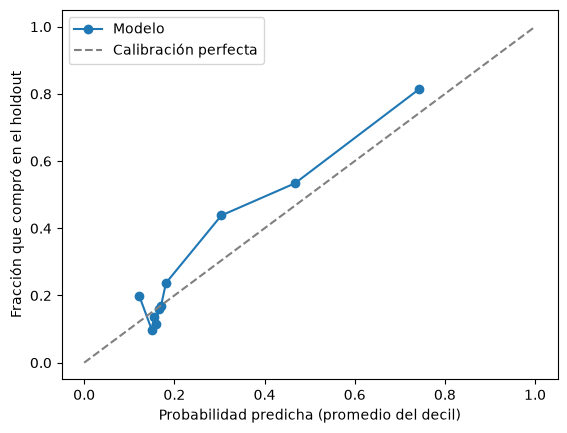

In [27]:
df["decil"] = pd.qcut(df.p_compra.rank(method="first"), 10, labels=False) + 1
cal = df.groupby("decil").agg(predicha=("p_compra", "mean"), observada=("Z", "mean"))
print(cal)

plt.plot(cal.predicha, cal.observada, "o-", label="Modelo")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
plt.xlabel("Probabilidad predicha (promedio del decil)")
plt.ylabel("Fracción que compró en el holdout")
plt.legend()
plt.show()

### 4.5 Evaluación con datos reales

| Clasificador | AUC |
|---|---|
| P(Z=1) del BG/NBD | 0.757 |
| Recencia tx | 0.763 |
| Frecuencia x | 0.758 |

El Brier del modelo fue 0.161 contra 0.206 de predecir la tasa base para
todos, así que las probabilidades sí aportan información.

Siendo honesta, el modelo **no ordena mejor** a los clientes que una sola
variable: la recencia y la frecuencia dan casi el mismo AUC (la diferencia
de 0.006 es ruido). En la curva de calibración, además, el modelo subestima
la probabilidad de compra en la mayoría de los deciles (por ejemplo, en el
decil 8 predice 0.30 y observamos 0.44), y los deciles 1 a 7 tienen
predicciones muy parecidas entre sí, es decir, casi no distingue entre ellos.

**Entonces, ¿qué ofrece el modelo?** Una sola variable solo da un orden, no
una probabilidad. El BG/NBD entrega probabilidades que se pueden usar para
estimar cuántos clientes van a comprar, permite cambiar el horizonte τ sin
reentrenar y combina x, tx y T en una cantidad interpretable. Si solo
queremos ordenar clientes para una campaña, con la recencia basta.

In [29]:
def ll_mbg(params, x, tx, T):
    r_, al_, a_, b_ = np.exp(params)
    t1 = betaln(a_, b_ + x + 1) - betaln(a_, b_) - (r_ + x) * np.log(al_ + T)
    t2 = betaln(a_ + 1, b_ + x) - betaln(a_, b_) - (r_ + x) * np.log(al_ + tx)
    ll = gammaln(r_ + x) - gammaln(r_) + r_ * np.log(al_) + np.logaddexp(t1, t2)
    return -ll.sum()

res = minimize(ll_mbg, np.log([0.25, 4, 0.8, 2.5]),
               args=(df.x.values, df.tx.values, df["T"].values),
               method="Nelder-Mead", options={"maxiter": 5000, "xatol": 1e-8, "fatol": 1e-8})
r2, al2, a2, b2 = np.exp(res.x)
print("MBG/NBD:", r2, al2, a2, b2, "logL =", -res.fun)

MBG/NBD: 0.5248431886688767 6.183085700158356 0.8913593322376553 1.6140019459306016 logL = -9582.135715553748


In [30]:
# MBG/NBD
def p_vivo_mbg(x, tx, T, r, alpha, a, b):
    x = np.asarray(x, float)
    return 1 / (1 + a / (b + x) * ((alpha + T) / (alpha + tx)) ** (r + x))

def ey_mbg(x, tx, T, tau, r, alpha, a, b):
    x = np.asarray(x, float)
    A = (alpha + T) / (alpha + T + tau)
    D = 1 + a / (b + x) * ((alpha + T) / (alpha + tx)) ** (r + x)
    num = 1 - A ** (r + x) * hyp2f1(r + x, b + x + 1, a + b + x, 1 - A)
    return (a + b + x) / (a - 1) * num / D

# BG/NBD (fórmula del 3.4)
def ey_bgnbd(x, tx, T, tau, r, alpha, a, b):
    x = np.asarray(x, float)
    A = (alpha + T) / (alpha + T + tau)
    D = 1 + (x > 0) * a / (b + np.maximum(x, 1) - 1) * ((alpha + T) / (alpha + tx)) ** (r + x)
    num = 1 - A ** (r + x) * hyp2f1(r + x, b + x, a + b + x - 1, 1 - A)
    return (a + b + x - 1) / (a - 1) * num / D

In [32]:
df["p_vivo_mbg"] = p_vivo_mbg(df.x, df.tx, df["T"], r2, al2, a2, b2)
df["p_compra_mbg"] = (df.p_vivo_mbg *
    (1 - ((al2 + df["T"]) / (al2 + df["T"] + 39)) ** (r2 + df.x)))

cero = df.x == 0
tabla = pd.DataFrame({
    "BG/NBD": [-9582.43, df.p_vivo[cero].mean(),
               roc_auc_score(df.Z, df.p_vivo), roc_auc_score(df.Z, df.p_compra),
               ey_bgnbd(df.x, df.tx, df["T"], 39, r, alpha, a, b).sum()],
    "MBG/NBD": [-res.fun, df.p_vivo_mbg[cero].mean(),
                roc_auc_score(df.Z, df.p_vivo_mbg), roc_auc_score(df.Z, df.p_compra_mbg),
                ey_mbg(df.x, df.tx, df["T"], 39, r2, al2, a2, b2).sum()],
}, index=["logL", "P(vivo) medio, x=0", "AUC P(vivo)", "AUC P(Z=1)", "Total pronosticado holdout"])
print(tabla)
print("Total real del holdout:", df.x_star.sum())

                                 BG/NBD      MBG/NBD
logL                       -9582.430000 -9582.135716
P(vivo) medio, x=0             1.000000     0.408807
AUC P(vivo)                    0.315792     0.686648
AUC P(Z=1)                     0.756887     0.760103
Total pronosticado holdout  1653.941259  1576.728297
Total real del holdout: 1882


### 4.6 Otro miembro de la familia: MBG/NBD

El MBG/NBD cambia una sola cosa del BG/NBD: el cliente también puede morir
justo después de su primera compra. Lo ajusté con mi propia verosimilitud
y comparé los dos modelos:

| | BG/NBD | MBG/NBD |
|---|---|---|
| logL | -9582.43 | -9582.14 |
| P(vivo) medio, x = 0 | 1.00 | 0.41 |
| AUC P(vivo) | 0.316 | 0.687 |
| AUC P(Z=1) | 0.757 | 0.760 |
| Total pronosticado (holdout) | 1,654 | 1,577 |

El total real fue 1,882, así que los dos se quedan cortos (el BG/NBD por
12% y el MBG/NBD por 16%).

**Ajuste.** La log-verosimilitud casi no cambia (0.3), o sea que los dos
ajustan casi igual. Los parámetros sí cambian bastante, porque cada modelo
reparte la "muerte" de forma distinta entre r, a y b.

**P(vivo) para x = 0.** En el BG/NBD vale 1 para todos, porque esos clientes
nunca han tenido la oportunidad de morir. En el MBG/NBD el promedio es 0.41,
porque alguien que compró una vez y no volvió ya puede estar muerto. Por eso
el AUC de P(vivo) sube de 0.316 a 0.687: ahora sí distingue entre los
clientes con x = 0.

**¿Por qué sigue valiendo la fórmula del 4.3?** Porque el argumento solo usa
que un cliente vivo que no compra sigue vivo, y que si está vivo la posterior
de λ es Gamma(r + x, α + T). Eso no cambia. Lo